In [8]:
# data process
"""
Stores NN-ready (coordinates, valence, target, group_id).
parameters: theta_delta=0.5, alpha_delta=0.9,
regularization delta=2.5e-5, softmin alpha=50.
fitted approximate Gaussian for valences, seed 42, fixed-fan default (or optional Delaunay one-ring extraction), CG tolerance and validity filters.
"""
from pathlib import Path
import numpy as np
from scipy.optimize import minimize
from scipy.spatial import Delaunay, QhullError
from scipy.special import logsumexp

SEED = 42
N_PATCHES = 60000              
THETA_DELTA = 0.5
ALPHA_DELTA = 0.9
DELTA = 2.5e-5
SOFTMIN_ALPHA = 50.0
CONNECTIVITY = "fan"        # "fan" preserves n; "delaunay triangulation" may change n
OUTPUT = Path("vasonet_dataset.npz")
rng = np.random.default_rng(SEED)

# n --Gaussian (u,segame^2) normal distribution
allowed_n = np.arange(3, 10) #3-9, not include 10
mu, sigma = 5.43, 1.62
valence_probs = np.exp(-0.5 * ((allowed_n - mu) / sigma) ** 2)
valence_probs /= valence_probs.sum()


def generate_ring(n):
    theta = 2 * np.pi * np.arange(n) / n
    theta += rng.uniform(-THETA_DELTA * 2 * np.pi / n,
                          THETA_DELTA * 2 * np.pi / n, size=n)
    theta += rng.uniform(-np.pi / 2, np.pi / 2)
    radial_perturbation = rng.uniform(-ALPHA_DELTA, ALPHA_DELTA, size=n)
    radius = 1.0 - radial_perturbation
    return np.column_stack([radius * np.cos(theta), radius * np.sin(theta)])


def get_one_ring(proposed_ring):
    """center's actual CCW one-ring. None means invalid/non-interior patch."""
    if CONNECTIVITY == "fan":
        ring = proposed_ring
    else:
        points = np.vstack([np.zeros((1, 2)), proposed_ring])
        try:
            simplices = Delaunay(points).simplices
        except QhullError:
            return None
        center_faces = simplices[np.any(simplices == 0, axis=1)]
        neighbors = np.unique(center_faces[center_faces != 0])
        if len(neighbors) < 3 or len(center_faces) != len(neighbors):
            return None  # center must be strictly interior
        ring = points[neighbors]
        ring = ring[np.argsort(np.arctan2(ring[:, 1], ring[:, 0]))]

    next_ring = np.roll(ring, -1, axis=0)
    signed_area2 = ring[:, 0] * next_ring[:, 1] - ring[:, 1] * next_ring[:, 0]
    if np.any(signed_area2 <= 1e-12):
        return None  # invalid orientation or center outside star kernel
    return ring


def quality_and_gradient(center, ring):
    """Regularized mean ratio and its analytic derivatives"""
    u = ring - center
    v = np.roll(u, -1, axis=0)

    # S=[u, (2v-u)/sqrt(3)].
    norm2 = np.sum(u*u, axis=1) + np.sum((2*v-u)**2, axis=1) / 3.0
    det = (2.0 / np.sqrt(3.0)) * (u[:, 0]*v[:, 1] - u[:, 1]*v[:, 0])
    root = np.sqrt(det**2 + 4*DELTA**2)
    numerator = np.where(det >= 0, det+root, 4*DELTA**2/(root-det))
    q = numerator / norm2

    d_norm2 = -(4.0/3.0) * (u+v)
    a = ring
    b = np.roll(ring, -1, axis=0)
    d_det = (2.0 / np.sqrt(3.0)) * np.column_stack((a[:, 1]-b[:, 1], b[:, 0]-a[:, 0]))
    d_numerator = (1 + det/root)[:, None] * d_det
    d_q = d_numerator/norm2[:, None] - (q/norm2)[:, None] * d_norm2
    return q, det, d_q


def objective(center, ring):
    """Minimize the negative LogSumExp smooth minimum, Eq. 10."""
    q, _, d_q = quality_and_gradient(center, ring)
    z = -SOFTMIN_ALPHA * q
    log_z = logsumexp(z)
    weights = np.exp(z - log_z)
    loss = log_z / SOFTMIN_ALPHA
    gradient = -(weights[:, None] * d_q).sum(axis=0)
    return loss, gradient


def optimize_center(ring):
    return minimize(objective, np.zeros(2), args=(ring,), method="CG", jac=True,
                    options={"gtol": 1e-7, "maxiter": 300})


def normalize_patch(ring, center):
    lower = ring.min(axis=0)
    upper = ring.max(axis=0)
    scale = (upper-lower).max()
    return (ring-lower)/scale, (center-lower)/scale


def create_dataset(count):
    coordinates, valence, targets, group_id = [], [], [], []
    quality_before, quality_after = [], []
    attempted = 0

    for sample_id in range(count):
        n = int(rng.choice(allowed_n, p=valence_probs))
        # Keep this sampled n fixed while retrying invalid geometries.
        for _ in range(500):
            attempted += 1
            ring = get_one_ring(generate_ring(n))
            if ring is not None:
                break
        else:
            raise RuntimeError(f"Failed to optimize a valence-{n} ring")

        center = optimize_center(ring).x
        q_before = quality_and_gradient(np.zeros(2), ring)[0].min()
        q_after = quality_and_gradient(center, ring)[0].min()
        ring, center = normalize_patch(ring, center)
        actual_n = len(ring)

        for k in range(actual_n):
            reordered = np.roll(ring, k, axis=0)
            padded = np.zeros((9, 2), dtype=np.float32)
            padded[:actual_n] = reordered
            coordinates.append(padded.reshape(18))
            valence.append(actual_n)
            targets.append(center.astype(np.float32))
            group_id.append(sample_id)
            quality_before.append(q_before)
            quality_after.append(q_after)

    np.savez_compressed(
        OUTPUT,
        coordinates=np.asarray(coordinates, dtype=np.float32),
        valence=np.asarray(valence, dtype=np.float32).reshape(-1, 1),
        target=np.asarray(targets, dtype=np.float32),
        group_id=np.asarray(group_id, dtype=np.int32),
        min_quality_before=np.asarray(quality_before, dtype=np.float32),
        min_quality_after=np.asarray(quality_after, dtype=np.float32),
    )
    print(f"Saved {count:,} patches / {len(valence):,} samples to {OUTPUT} (attempts: {attempted:,})")


if __name__ == "__main__":
    create_dataset(N_PATCHES)

Saved 60,000 patches / 331,277 samples to vasonet_dataset.npz (attempts: 62,939)


In [9]:
# model process
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(SEED)

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

class VASONet(nn.Module):
    @staticmethod
    def init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)

    def __init__(self):
        super().__init__()
        self.geo_mlp = nn.Sequential(
            nn.Linear(18, 320),nn.ReLU(),nn.Dropout(0.0064)
        )

        self.topo_mlp = nn.Sequential(
            nn.Linear(1, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(352, 512), nn.ReLU(), nn.Dropout(0.0330),
            nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.0330),
            nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.0330),
            nn.Linear(512, 2)
        )
        self.apply(self.init_weights)

    def forward(self, coordinates, valence):
        x = coordinates.reshape(-1, 18).float()
        n = valence.reshape(-1, 1).float()

        hg = self.geo_mlp(x)
        ht = self.topo_mlp(n)

        h = torch.cat([hg, ht], dim=1)
        return self.decoder(h)

Valence_MLP = VASONet().to(device)
# setting
loss = nn.MSELoss()
learning_rates = 6.5e-4
epochs = 200
batch_size = 64
optimizer = torch.optim.Adam( Valence_MLP.parameters(), lr=learning_rates, betas=(0.9, 0.999) )
lr_rates = torch.optim.lr_scheduler.ExponentialLR( optimizer, gamma=0.916 )


print(Valence_MLP)


Using cuda device
VASONet(
  (geo_mlp): Sequential(
    (0): Linear(in_features=18, out_features=320, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0064, inplace=False)
  )
  (topo_mlp): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=32, bias=True)
    (7): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=352, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.033, inplace=False)
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.033, inplace=False)
    (6): Linear(in_features=512, out_features=512, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.033, inplace=False)
    (9): Linear(in_features=512, out_features=2, bias=True)
  )
)


In [10]:
# train process
with np.load(OUTPUT) as data:
    coordinates = torch.from_numpy(data["coordinates"])
    valence = torch.from_numpy(data["valence"])
    targets = torch.from_numpy(data["target"])
    group_id = torch.from_numpy(data["group_id"])

# Split patches 70% / 20% / 10%, keeping cyclic reorderings together.
generator = torch.Generator().manual_seed(SEED)
groups = torch.unique(group_id)
groups = groups[torch.randperm(len(groups), generator=generator)]
n_train = int(0.7 * len(groups))
n_val = int(0.2 * len(groups))
train_mask = torch.isin(group_id, groups[:n_train])
val_mask = torch.isin(group_id, groups[n_train:n_train + n_val])
test_mask = torch.isin(group_id, groups[n_train + n_val:])

train_dataset = TensorDataset(coordinates[train_mask], valence[train_mask], targets[train_mask])
val_dataset = TensorDataset(coordinates[val_mask], valence[val_mask], targets[val_mask])
test_dataset = TensorDataset(coordinates[test_mask], valence[test_mask], targets[test_mask])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Samples: train={len(train_dataset):,}, val={len(val_dataset):,}, test={len(test_dataset):,}")


def evaluate_mse(loader):
    Valence_MLP.eval()
    total_loss = 0.0
    with torch.no_grad():
        for coordinates_batch, valence_batch, target_batch in loader:
            coordinates_batch = coordinates_batch.to(device)
            valence_batch = valence_batch.to(device)
            target_batch = target_batch.to(device)
            prediction = Valence_MLP(coordinates_batch, valence_batch)
            total_loss += loss(prediction, target_batch).item() * len(target_batch)
    return total_loss / len(loader.dataset)


history = {"train": [], "val": [], "test": []}
for epoch in range(1, epochs + 1):
    Valence_MLP.train()
    total_train_loss = 0.0
    for coordinates_batch, valence_batch, target_batch in train_loader:
        coordinates_batch = coordinates_batch.to(device)
        valence_batch = valence_batch.to(device)
        target_batch = target_batch.to(device)

        optimizer.zero_grad(set_to_none=True)
        prediction = Valence_MLP(coordinates_batch, valence_batch)
        batch_loss = loss(prediction, target_batch)
        batch_loss.backward()
        optimizer.step()
        total_train_loss += batch_loss.item() * len(target_batch)

    train_mse = total_train_loss / len(train_dataset)
    val_mse = evaluate_mse(val_loader)
    test_mse = evaluate_mse(test_loader)
    history["train"].append(train_mse)
    history["val"].append(val_mse)
    history["test"].append(test_mse)
    print(
        f"Epoch {epoch:03d}/{epochs} | Train MSE: {train_mse:.8f} | "
        f"Val MSE: {val_mse:.8f} | Test MSE: {test_mse:.8f}",
        flush=True,
    )
    lr_rates.step()

torch.save(Valence_MLP.state_dict(), "MLP.pt")
print("Saved final model weights to MLP.pt")


Samples: train=232,215, val=66,126, test=32,936
Epoch 001/200 | Train MSE: 0.00478952 | Val MSE: 0.00310688 | Test MSE: 0.00308938
Epoch 002/200 | Train MSE: 0.00285350 | Val MSE: 0.00230486 | Test MSE: 0.00230908
Epoch 003/200 | Train MSE: 0.00226042 | Val MSE: 0.00187808 | Test MSE: 0.00189147
Epoch 004/200 | Train MSE: 0.00192916 | Val MSE: 0.00163596 | Test MSE: 0.00164900
Epoch 005/200 | Train MSE: 0.00170296 | Val MSE: 0.00145600 | Test MSE: 0.00147246
Epoch 006/200 | Train MSE: 0.00154027 | Val MSE: 0.00137967 | Test MSE: 0.00140232
Epoch 007/200 | Train MSE: 0.00141618 | Val MSE: 0.00127569 | Test MSE: 0.00130539
Epoch 008/200 | Train MSE: 0.00130443 | Val MSE: 0.00121820 | Test MSE: 0.00125065
Epoch 009/200 | Train MSE: 0.00121958 | Val MSE: 0.00114553 | Test MSE: 0.00118179
Epoch 010/200 | Train MSE: 0.00114779 | Val MSE: 0.00105567 | Test MSE: 0.00108043
Epoch 011/200 | Train MSE: 0.00108527 | Val MSE: 0.00105351 | Test MSE: 0.00108214
Epoch 012/200 | Train MSE: 0.00103072 |

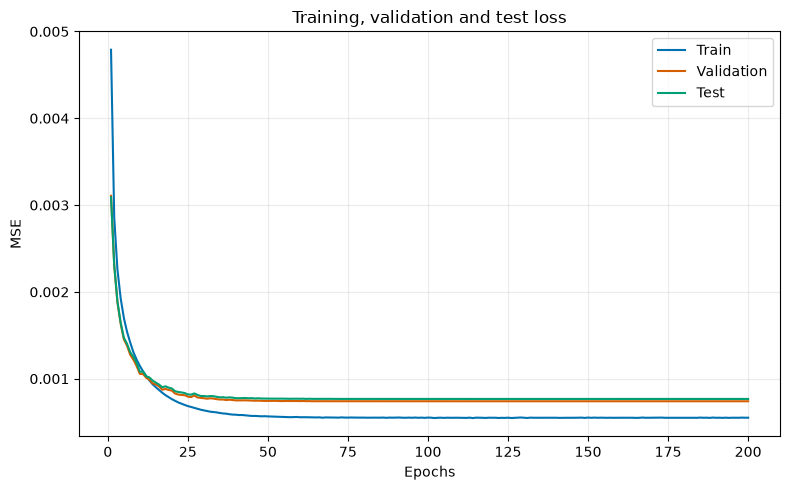

In [11]:
# train / validation / test loss visualization
import matplotlib.pyplot as plt

epoch_axis = range(1, len(history["train"]) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epoch_axis, history["train"], label="Train", color="#0072B2", linestyle="-")
ax.plot(epoch_axis, history["val"], label="Validation", color="#D55E00", linestyle="-")
ax.plot(epoch_axis, history["test"], label="Test", color="#009E73", linestyle="-")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.set_title("Training, validation and test loss")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


In [12]:
# Test case generation and smoothing

# Mesh generation; reuse NumPy and Delaunay imported above.
from matplotlib.path import Path as PolygonPath


def sample_polygon(corners, spacing):
    """Sample straight edges without duplicating their shared endpoints."""
    corners = np.asarray(corners, dtype=float)
    edges = []
    for start, end in zip(corners, np.roll(corners, -1, axis=0)):
        n = int(np.ceil(np.linalg.norm(end - start) / spacing))
        edges.append(start + np.arange(n)[:, None] / n * (end - start))
    return np.vstack(edges)


def ellipse_boundary(center, axes, angle, spacing):
    """Polygonal approximation; angle is in radians."""
    n = int(np.ceil(2 * np.pi * max(axes) / spacing))
    theta = np.linspace(0, 2 * np.pi, n, endpoint=False)
    points = np.column_stack((np.cos(theta), np.sin(theta))) * axes
    c, s = np.cos(angle), np.sin(angle)
    return points @ np.array([[c, s], [-s, c]]) + center


def build_test_mesh(outer, holes, n_interior, seed):
    """Recover polygon boundary edges before classifying Delaunay faces."""
    loops = [outer, *holes]
    paths = [PolygonPath(loop) for loop in loops]

    def inside(points):
        mask = paths[0].contains_points(points)
        for path in paths[1:]:
            mask &= ~path.contains_points(points)
        return mask

    mesh_rng = np.random.default_rng(seed)
    lower, upper = outer.min(axis=0), outer.max(axis=0)
    interior = np.empty((0, 2))
    while len(interior) < n_interior:
        candidates = mesh_rng.uniform(lower, upper, size=(2 * n_interior, 2))
        interior = np.vstack((interior, candidates[inside(candidates)]))
    interior = interior[:n_interior]

    for _ in range(12):
        n_boundary = sum(map(len, loops))
        V = np.vstack([*loops, interior])
        F = Delaunay(V).simplices
        edges = np.sort(F[:, [[0, 1], [1, 2], [2, 0]]].reshape(-1, 2), axis=1)
        edge_set = set(map(tuple, edges))
        missing = []
        boundary_edges = []
        offset = 0
        for loop in loops:
            ids = np.arange(offset, offset + len(loop))
            segments = [tuple(sorted((i, j))) for i, j in zip(ids, np.roll(ids, -1))]
            boundary_edges.extend(segments)
            missing.append(np.array([edge not in edge_set for edge in segments]))
            offset += len(loop)
        if not any(mask.any() for mask in missing):
            break
        # Midpoints lie on the same polygon, so refinement preserves geometry.
        refined = []
        for loop, mask in zip(loops, missing):
            points = []
            for start, end, split in zip(loop, np.roll(loop, -1, axis=0), mask):
                points.append(start)
                if split:
                    points.append((start + end) / 2)
            refined.append(np.asarray(points))
        loops = refined
    else:
        raise RuntimeError("Boundary recovery failed; use a constrained mesher.")

    # Once all boundary segments are mesh edges, no face can cross a hole.
    F = F[inside(V[F].mean(axis=1))].copy()
    a, b, c = V[F[:, 0]], V[F[:, 1]], V[F[:, 2]]
    signed_area2 = (b[:, 0] - a[:, 0]) * (c[:, 1] - a[:, 1]) - (b[:, 1] - a[:, 1]) * (c[:, 0] - a[:, 0])
    flipped = signed_area2 < 0
    F[flipped] = F[flipped][:, [0, 2, 1]]

    edges, counts = np.unique(
        np.sort(F[:, [[0, 1], [1, 2], [2, 0]]].reshape(-1, 2), axis=1),
        axis=0, return_counts=True,
    )
    boundary_mask = np.zeros(len(V), dtype=bool)
    boundary_mask[np.unique(edges[counts == 1])] = True
    assert set(map(tuple, edges[counts == 1])) == set(boundary_edges), "Boundary segments changed."
    assert np.all(np.abs(signed_area2) > 1e-14), "Degenerate triangle."
    assert counts.max() == 2, "Non-manifold mesh."
    assert np.array_equal(np.flatnonzero(boundary_mask), np.arange(n_boundary)), "Unexpected boundary."
    assert len(np.unique(F)) == len(V), "Unused mesh vertices."
    return dict(V=V, F=F, boundary_mask=boundary_mask,
                free_nodes=np.flatnonzero(~boundary_mask))

# Representative geometries
BOUNDARY_SPACING = 0.10
h = BOUNDARY_SPACING

square = sample_polygon([[0, 0], [1, 0], [1, 1], [0, 1]], h)

theta = np.pi / 2 + np.arange(10) * np.pi / 5
radii = np.where(np.arange(10) % 2 == 0, 0.45, 0.22)
star = sample_polygon(radii[:, None] * np.column_stack((np.cos(theta), np.sin(theta))), h)
circle = ellipse_boundary((0, 0), (1, 1), 0, h)

plate = sample_polygon([[0, 0], [2, 0], [2, 2], [0, 2]], h)
holes = [
    ellipse_boundary((0.70, 0.70), (0.48, 0.48), 0, h),
    ellipse_boundary((1.40, 1.40), (0.62, 0.25), -np.pi / 4, h),
]

meshes = {
    "Unstructured Square": build_test_mesh(square, [], 180, SEED),
    "Circle with Star Hole": build_test_mesh(circle, [star], 450, SEED + 1),
    "Perforated Plate": build_test_mesh(plate, holes, 400, SEED + 2),
}

# Topological one-rings, metrics, and three independent smoothing routines.
from time import perf_counter
from collections import Counter


def build_rings(mesh):
    successors = {int(i): {} for i in mesh["free_nodes"]}
    for a, b, c in mesh["F"]:
        for i, j, k in ((a, b, c), (b, c, a), (c, a, b)):
            if i in successors:
                successors[i][int(j)] = int(k)
    rings = {}
    for i, following in successors.items():
        start = min(following)
        ring = [start]
        for _ in range(len(following) - 1):
            ring.append(following[ring[-1]])
        assert following[ring[-1]] == start and len(set(ring)) == len(following)
        rings[i] = np.asarray(ring, dtype=int)
    return rings


def triangle_quality(V, F):
    a, b, c = V[F[:, 0]], V[F[:, 1]], V[F[:, 2]]
    cross = (b[:, 0]-a[:, 0])*(c[:, 1]-a[:, 1]) - (b[:, 1]-a[:, 1])*(c[:, 0]-a[:, 0])
    denominator = ((a-b)**2 + (b-c)**2 + (c-a)**2).sum(axis=1)
    return 2*np.sqrt(3)*cross/denominator


def mesh_metrics(V, F):
    q = triangle_quality(V, F)
    assert np.isfinite(V).all() and np.isfinite(q).all()
    return {"q_min": float(q.min()), "q_mean": float(q.mean()),
            "inverted": int((q < 0).sum()), "degenerate": int((q == 0).sum())}


def pr_cg_node(center, ring):
    # Translation improves numerical conditioning without changing the objective.
    result = optimize_center(ring - center)
    assert np.isfinite(result.x).all() and np.isfinite(result.fun)
    return center + result.x, result.status


def laplacian_smoothing(mesh, rings, sweeps):
    V = mesh["V"].copy()
    history = [mesh_metrics(V, mesh["F"])]
    start = perf_counter()
    for _ in range(sweeps):
        for i in mesh["free_nodes"]:
            V[i] = V[rings[i]].mean(axis=0)
        history.append(mesh_metrics(V, mesh["F"]))
    return {"V": V, "history": history, "seconds": perf_counter()-start}


def optimization_smoothing(mesh, rings, sweeps):
    V = mesh["V"].copy()
    history, statuses = [mesh_metrics(V, mesh["F"])], Counter()
    start = perf_counter()
    for _ in range(sweeps):
        for i in mesh["free_nodes"]:
            V[i], status = pr_cg_node(V[i], V[rings[i]])
            statuses[status] += 1
        history.append(mesh_metrics(V, mesh["F"]))
    return {"V": V, "history": history, "seconds": perf_counter()-start,
            "cg_status": dict(statuses)}


def neural_smoothing(mesh, rings, model, sweeps):
    V = mesh["V"].copy()
    history, statuses = [mesh_metrics(V, mesh["F"])], Counter()
    model.eval()
    model_device = next(model.parameters()).device
    padded = np.zeros((9, 2), dtype=np.float32)
    n = torch.empty((1, 1), dtype=torch.float32, device=model_device)
    start = perf_counter()
    with torch.inference_mode():
        for _ in range(sweeps):
            for i in mesh["free_nodes"]:
                ring = V[rings[i]]
                valence = len(ring)
                if not 3 <= valence <= 9:
                    V[i], status = pr_cg_node(V[i], ring)
                    statuses[status] += 1
                    continue
                lower = ring.min(axis=0)
                scale = np.ptp(ring, axis=0).max()
                padded.fill(0)
                padded[:valence] = (ring-lower)/scale
                coordinates = torch.from_numpy(padded.reshape(1, 18)).to(model_device)
                n.fill_(valence)
                prediction = model(coordinates, n)[0].cpu().numpy()
                V[i] = prediction*scale + lower
            history.append(mesh_metrics(V, mesh["F"]))
    return {"V": V, "history": history, "seconds": perf_counter()-start,
            "fallback_updates": sum(statuses.values()), "cg_status": dict(statuses)}

# Three independent runs, ten ascending-node Gauss-Seidel sweeps each.
GLOBAL_SWEEPS = 10
nn_model = VASONet().cpu()
nn_model.load_state_dict(torch.load("MLP.pt", map_location="cpu", weights_only=True))
torch.set_num_threads(1)

results = {}
for case_name, mesh in meshes.items():
    rings = build_rings(mesh)
    results[case_name] = {
        "Original": {"V": mesh["V"].copy(), "history": [mesh_metrics(mesh["V"], mesh["F"])], "seconds": 0.0},
        "Laplacian": laplacian_smoothing(mesh, rings, GLOBAL_SWEEPS),
        "PR-CG": optimization_smoothing(mesh, rings, GLOBAL_SWEEPS),
        "NN": neural_smoothing(mesh, rings, nn_model, GLOBAL_SWEEPS),
    }
    for method, result in results[case_name].items():
        assert np.array_equal(result["V"][mesh["boundary_mask"]], mesh["V"][mesh["boundary_mask"]])
        if method != "Original":
            assert len(result["history"]) == GLOBAL_SWEEPS + 1
    print(f"{case_name}: completed {GLOBAL_SWEEPS} sweeps for all three methods.", flush=True)


Unstructured Square: completed 10 sweeps for all three methods.
Circle with Star Hole: completed 10 sweeps for all three methods.
Perforated Plate: completed 10 sweeps for all three methods.


| Case | Method | q min | q mean | Inverted final / peak | Time (s) | s / node update | Speedup vs PR-CG |
|---|---|---:|---:|---:|---:|---:|---:|
| Unstructured Square | Original | 0.1159 | 0.7056 | 0 / 0 | — | — | — |
| Unstructured Square | Laplacian | 0.2953 | 0.9028 | 0 / 0 | 0.0103 | 5.722e-06 | 711.23x |
| Unstructured Square | PR-CG | 0.5992 | 0.8720 | 0 / 0 | 7.3256 | 4.070e-03 | 1.00x |
| Unstructured Square | NN | 0.4608 | 0.8728 | 0 / 0 | 0.3554 | 1.974e-04 | 20.61x |
| Circle with Star Hole | Original | 0.0125 | 0.6995 | 0 / 0 | — | — | — |
| Circle with Star Hole | Laplacian | 0.0614 | 0.8734 | 0 / 1 | 0.0168 | 3.742e-06 | 862.40x |
| Circle with Star Hole | PR-CG | 0.1169 | 0.8267 | 0 / 0 | 14.5216 | 3.227e-03 | 1.00x |
| Circle with Star Hole | NN | 0.2415 | 0.8368 | 0 / 0 | 0.9239 | 2.053e-04 | 15.72x |
| Perforated Plate | Original | 0.0496 | 0.6910 | 0 / 0 | — | — | — |
| Perforated Plate | Laplacian | 0.2299 | 0.8662 | 0 / 0 | 0.0153 | 3.826e-06 | 819.68x |
| Perforated Plate | PR-CG | 0.5554 | 0.8218 | 0 / 0 | 12.5439 | 3.136e-03 | 1.00x |
| Perforated Plate | NN | 0.3829 | 0.8342 | 0 / 0 | 0.8329 | 2.082e-04 | 15.06x |

| Case | Method | Converged CG updates | Precision / line-search stops | Other CG stops | CG fallback updates |
|---|---|---:|---:|---:|---:|
| Unstructured Square | PR-CG | 1614 | 186 | 0 | 0 |
| Unstructured Square | NN | 0 | 0 | 0 | 0 |
| Circle with Star Hole | PR-CG | 4005 | 495 | 0 | 0 |
| Circle with Star Hole | NN | 36 | 4 | 0 | 40 |
| Perforated Plate | PR-CG | 3528 | 472 | 0 | 0 |
| Perforated Plate | NN | 38 | 2 | 0 | 40 |

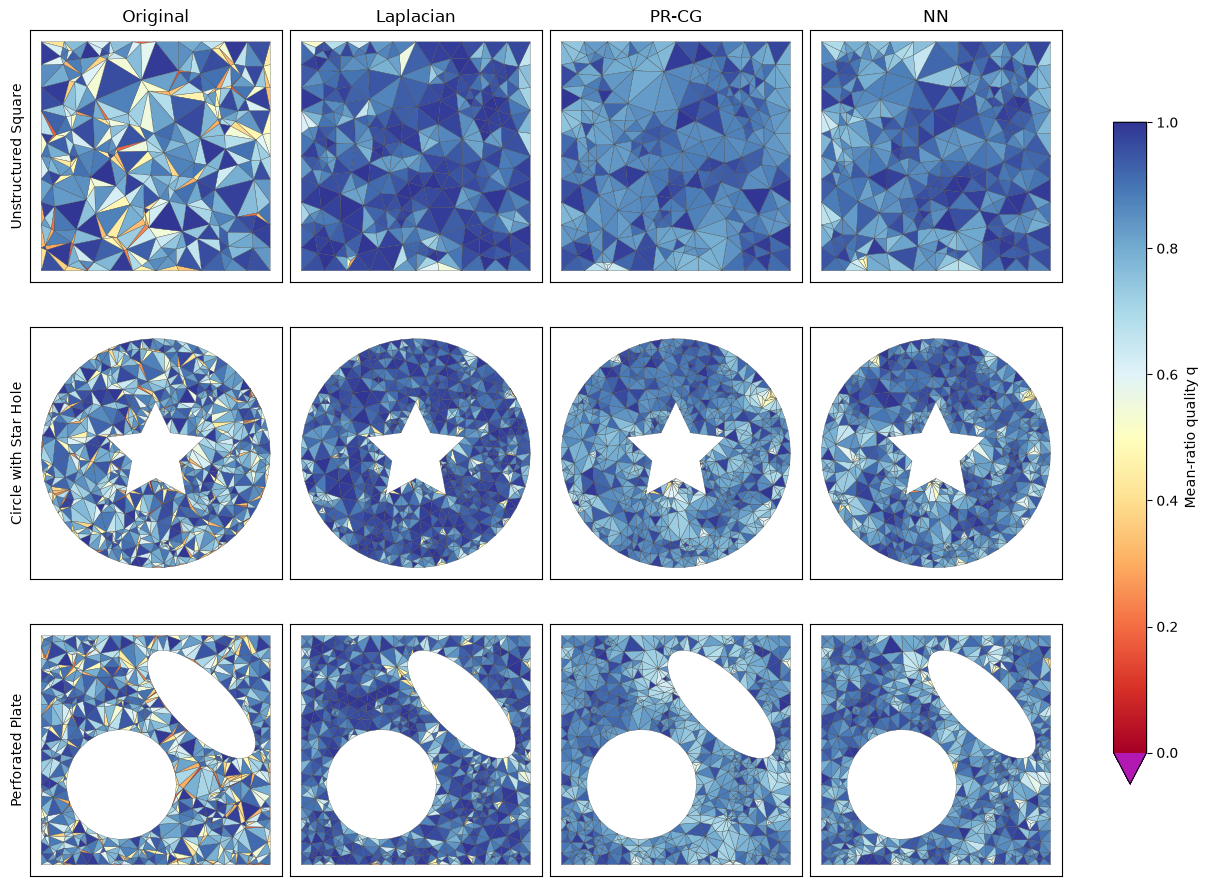

In [13]:
# Visualization: tables and final mesh comparison

# Summary tables; unimplemented paper metrics are not estimated.
from IPython.display import Markdown, display

rows = [
    "| Case | Method | q min | q mean | Inverted final / peak | Time (s) | s / node update | Speedup vs PR-CG |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for case_name, case_results in results.items():
    updates = GLOBAL_SWEEPS * len(meshes[case_name]["free_nodes"])
    baseline = case_results["PR-CG"]["seconds"]
    for method, result in case_results.items():
        metrics = result["history"][-1]
        peak = max(h["inverted"] for h in result["history"])
        elapsed = result["seconds"]
        timing = (f"{elapsed:.4f} | {elapsed/updates:.3e} | {baseline/elapsed:.2f}x"
                  if method != "Original" else "— | — | —")
        rows.append(f"| {case_name} | {method} | {metrics['q_min']:.4f} | {metrics['q_mean']:.4f} | "
                    f"{metrics['inverted']} / {peak} | {timing} |")
display(Markdown("\n".join(rows)))


# Keep solver diagnostics visible without mixing them into geometric quality.
rows = ["| Case | Method | Converged CG updates | Precision / line-search stops | Other CG stops | CG fallback updates |",
        "|---|---|---:|---:|---:|---:|"]
for case_name, case_results in results.items():
    for method in ("PR-CG", "NN"):
        result = case_results[method]
        status = result["cg_status"]
        rows.append(f"| {case_name} | {method} | {status.get(0, 0)} | {status.get(2, 0)} | "
                    f"{sum(v for k, v in status.items() if k not in (0, 2))} | "
                    f"{result.get('fallback_updates', 0)} |")
display(Markdown("\n".join(rows)))

# Final mesh comparison: one shared linear scale for all twelve panels.
quality_cmap = plt.get_cmap("RdYlBu").copy()
quality_cmap.set_under("#B218B2")  # q < 0: inverted elements, outside the valid range.
fig, axes = plt.subplots(3, 4, figsize=(12, 9), constrained_layout=True)
for row, (case_name, mesh) in enumerate(meshes.items()):
    for col, (method, result) in enumerate(results[case_name].items()):
        ax = axes[row, col]
        V, F = result["V"], mesh["F"]
        image = ax.tripcolor(V[:, 0], V[:, 1], F, facecolors=triangle_quality(V, F),
                     cmap=quality_cmap, vmin=0, vmax=1, edgecolors="0.25", linewidth=0.22)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(method)
        if col == 0:
            ax.set_ylabel(case_name)
fig.colorbar(image, ax=axes,
             ticks=np.linspace(0, 1, 6), extend="min", label="Mean-ratio quality q", shrink=0.75)
plt.show()
